# Bigram Character-Level Language Model

#### loading the data and libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

In [2]:
words = open('../names.txt', 'r').read().splitlines()
print(f"{len(words)} names, length {min(len(w) for w in words)}–{max(len(w) for w in words)}")
words[:5]

32033 names, length 2–15


['emma', 'olivia', 'ava', 'isabella', 'sophia']

In [3]:
print(len(words))
print(min(len(w) for w in words))
print(max(len(w) for w in words))

32033
2
15


#### counting

In [4]:
#mapping

letters = sorted(list(set(''.join(words))))
str_to_int = {s:i+1 for i, s in enumerate(letters)}
str_to_int['.'] = 0

int_to_str = {i:s for s, i in str_to_int.items()}

In [5]:
N = torch.zeros((27, 27), dtype = torch.int32)

for w in words:
    characters =['.'] + list(w) + ['.']
    for ch1, ch2 in zip(characters, characters[1:]):
        int1 = str_to_int[ch1]
        int2 = str_to_int[ch2]
        N[int1, int2] += 1

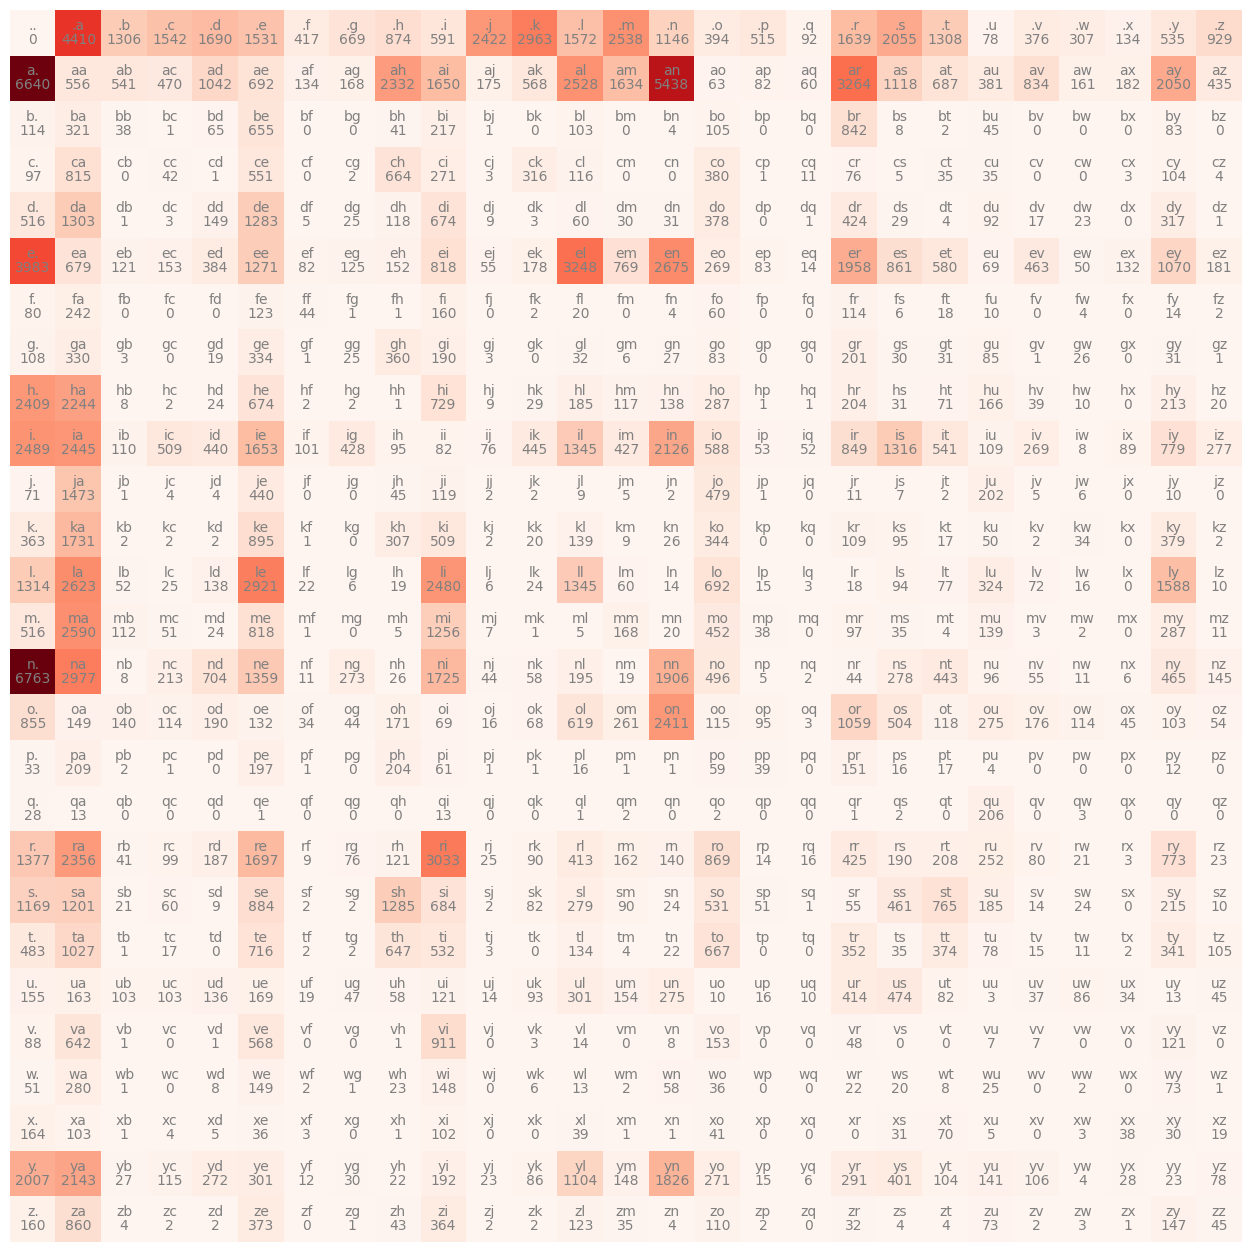

In [6]:


plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Reds')
for i in range(27):
    for j in range(27):
        bigram_str = int_to_str[i] + int_to_str[j]
        plt.text(j, i, bigram_str, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off');

#### probabilities

In [7]:
P = (N+1).float()
P_row_sums = P.sum(1, keepdim=True)
P /= P_row_sums

#### Sampling

In [8]:
g = torch.Generator().manual_seed(1234)

for i in range(10):

    output = []
    index = 0
    while True:
        p = P[index]
        index = torch.multinomial(p, num_samples=1, replacement = True, generator = g).item() #.item() so get number and not tensor[number]

        output.append(int_to_str[index])
        if index==0:
            break
    print(''.join(output))
        

kyason.
kanana.
milaveela.
ra.
drisan.
lurtolisyrsh.
tobay.
n.
myeeahare.
chucinailelulelone.


#### log loss

In [9]:
log_likelihood = 0.0
n = 0.0

for w in words:
    characters =['.'] + list(w) + ['.']
    for ch1, ch2 in zip(characters, characters[1:]):
        int1 = str_to_int[ch1]
        int2 = str_to_int[ch2]
        prob = P[int1, int2]
        log_prob = torch.log(prob)
        log_likelihood += log_prob
        n+=1

neg_log_likelihood = - log_likelihood
avg = neg_log_likelihood / n
print(avg)


tensor(2.4544)


## Neural network

#### Training set

In [10]:
Xs = []
Ys = []

for w in words:
    characters =['.'] + list(w) + ['.']
    for ch1, ch2 in zip(characters, characters[1:]):
        int1 = str_to_int[ch1]
        int2 = str_to_int[ch2]

        Xs.append(int1)
        Ys.append(int2)

Xs = torch.tensor(Xs)
Ys = torch.tensor(Ys)



#### One hot enconding + forward pass

In [11]:
x_encoded = F.one_hot(Xs, num_classes = 27).float()
num = Xs.nelement()

g = torch.Generator().manual_seed(1234)
W = torch.randn((27, 27), requires_grad=True, generator = g)

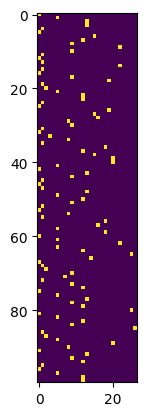

In [12]:
plt.imshow(x_encoded[:100])

### backpropagating

In [13]:
learning_rate = 5

for i in range(1000):
    # forward
    logits = x_encoded @ W
    counts = logits.exp()
    probs = counts / counts.sum(1, keepdims=True)
    loss = -probs[torch.arange(num), Ys].log().mean() + 0.01 * (W**2).mean()  # L2 regularisation

    # backward
    W.grad = None
    loss.backward()

    # update
    W.data += -learning_rate * W.grad

    if i % 100 == 0:
        print(f"{i:4d}: {loss.item():.4f}")
print(f"final: {loss.item():.4f}")
        

   0: 3.8207
 100: 2.6795
 200: 2.5742
 300: 2.5380
 400: 2.5202
 500: 2.5099
 600: 2.5032
 700: 2.4986
 800: 2.4952
 900: 2.4926
final: 2.4907


In [14]:
P_net = W.exp()
P_net = P_net / P_net.sum(1, keepdims=True)

g = torch.Generator().manual_seed(1234)

for i in range(10):

    output = []
    index = 0
    while True:
        p = P_net[index]
        index = torch.multinomial(p, num_samples=1, replacement = True, generator = g).item() #.item() so get number and not tensor[number]
        output.append(int_to_str[index])
        if index==0:
            break
    print(''.join(output))

kyason.
kanana.
milaveela.
ra.
drisan.
lurtolisyricohobay.
n.
myaeahare.
chucinailelulelone.
eda.
